# Project 2, Moira's Dream Car

Working notebook. Reusable code lives in `src/`.

In [2]:
import sys
sys.path.insert(0, 'src')

import torch
import warnings
from matplotlib import pyplot as plt
from scipy.stats import spearmanr

from constants import *
from data import load_data, build_ratings, split_indices, make_loaders, denorm
from eda import correlation_matrix, top_decile, overlap_lift
from viz import show, show_tensor, rating_histograms
from regressor import make_regressor, train_regressor, constant_baseline, predict, evaluate

warnings.filterwarnings("ignore")
print(device)

/fp/homes01/u01/ec-armans/.venvImg/lib/python3.11/site-packages/quix/data/dataset.py:56: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


cuda


## Data

In [3]:
data = load_data()
ratings = build_ratings(data)

img, scores = data[42]
print(len(data), img.shape, scores.flatten())

6000 torch.Size([3, 96, 128]) tensor([6, 1, 5, 9, 3, 2])


## S1, preference structure

The raters differ sharply in generosity. Moira sits at 1 to 2 and rarely goes
above 7, Ferdinando peaks at 9. Different marginals alone do not imply
disagreement, so the ranking correlation is what settles it.

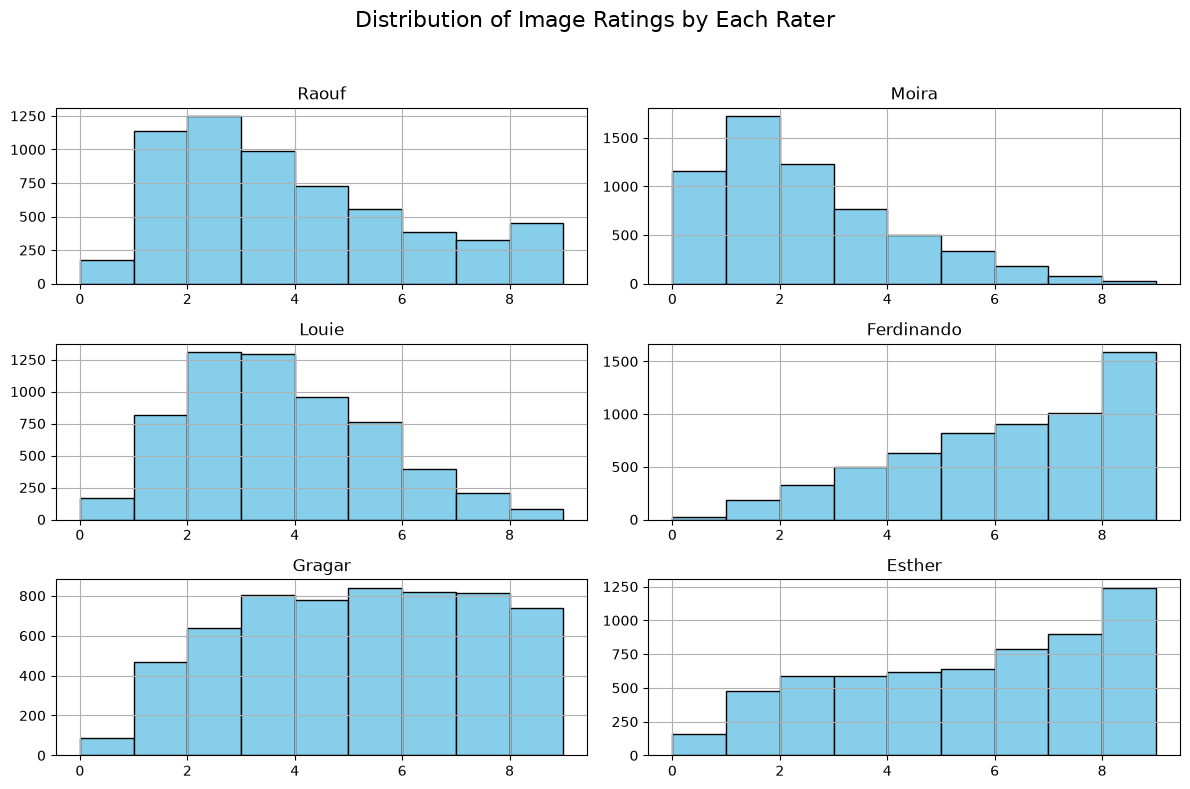

In [4]:
rating_histograms(ratings)
plt.show()

In [5]:
correlation_matrix(ratings).round(3)

,Raouf,Moira,Louie,Ferdinando,Gragar,Esther
Raouf,1.000,0.052,-0.111,-0.181,0.007,-0.435
Moira,0.052,1.000,-0.175,-0.271,0.121,0.227
Louie,-0.111,-0.175,1.000,0.365,-0.312,0.194
Ferdinando,-0.181,-0.271,0.365,1.000,-0.359,-0.077
Gragar,0.007,0.121,-0.312,-0.359,1.000,-0.059
Esther,-0.435,0.227,0.194,-0.077,-0.059,1.000


In [6]:
spearmanr(ratings['Moira'], ratings['Ferdinando'])

SignificanceResult(statistic=np.float64(-0.2710463185016363), pvalue=np.float64(1.5705000894171188e-101))

Their top deciles overlap three times less than chance, so the region that
satisfies both is thin: 55 cars out of 6000.

In [7]:
ov = overlap_lift(ratings, 'Moira', 'Ferdinando')
print({k: v for k, v in ov.items() if k != 'indices'})

shared_liked_cars = ov['indices']
moira_top = top_decile(ratings, 'Moira')
ferdinando_top = top_decile(ratings, 'Ferdinando')

{'n_a': 627, 'n_b': 1590, 'shared': 55, 'expected': 166.155, 'lift': 0.3310162197947699}


The conflict axis is body type, with colour following from it. Moira likes
sports cars in saturated colours, Ferdinando likes everyday vehicles in white
and silver. The shared set is his taste that she tolerates: almost every pair
reads M5 F9.

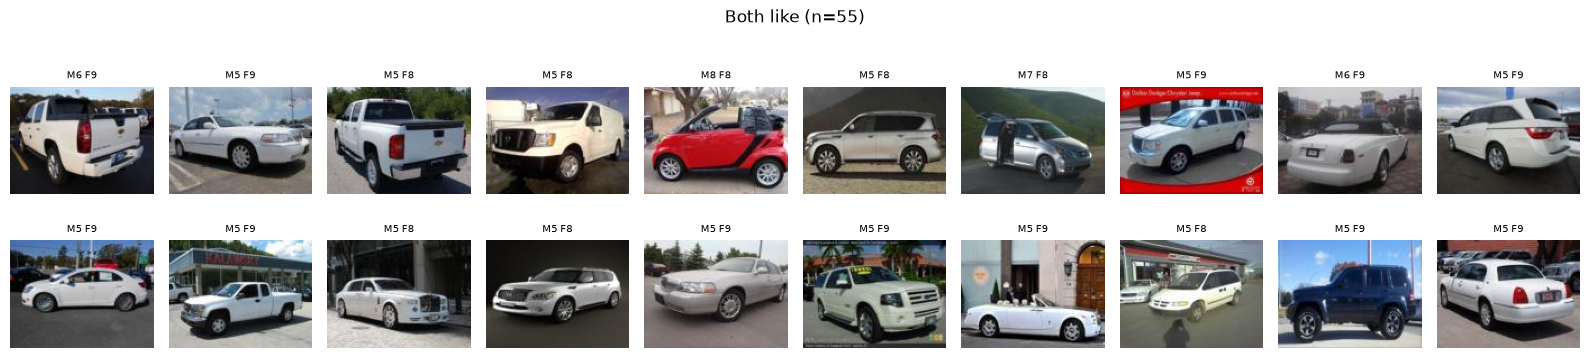

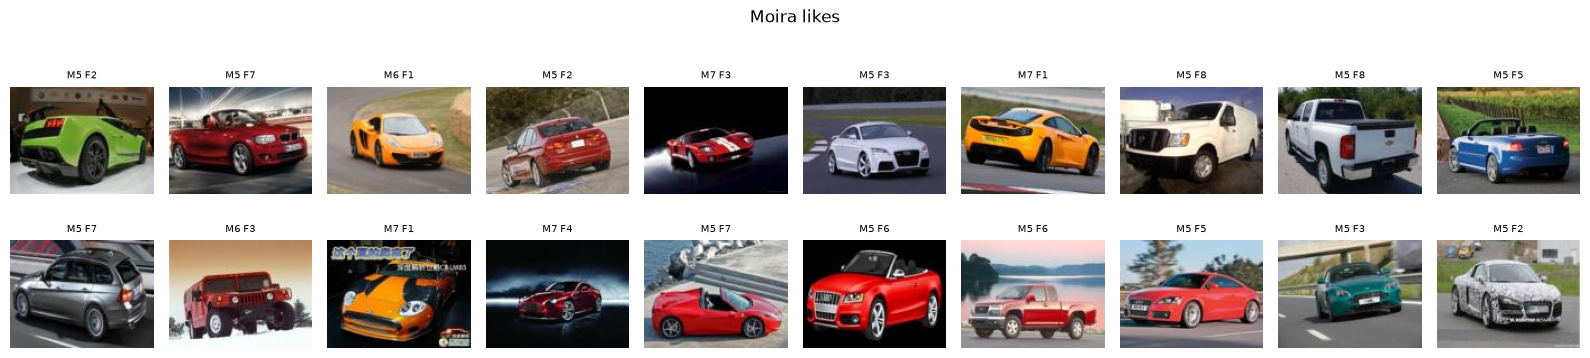

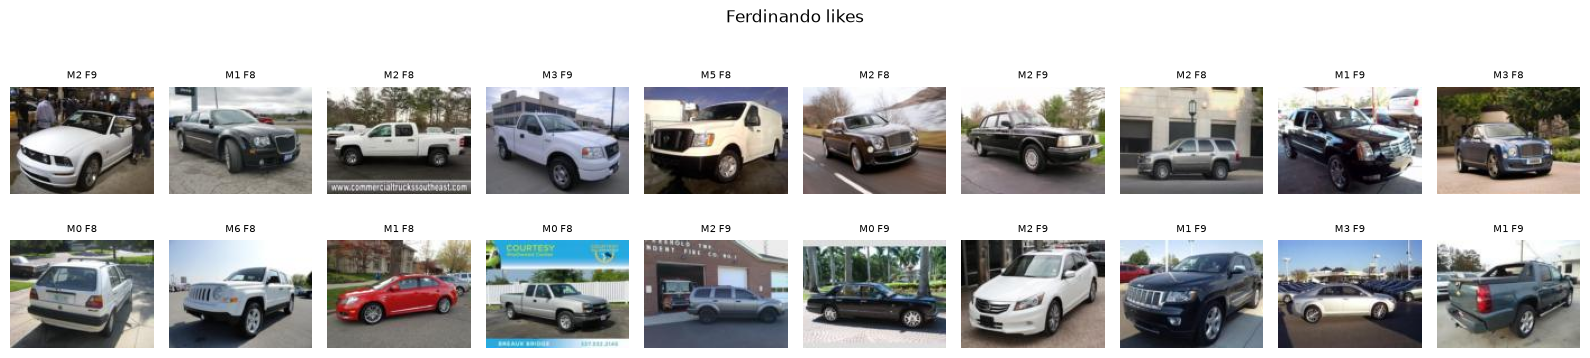

In [8]:
show(data, shared_liked_cars, f"Both like (n={len(shared_liked_cars)})")
show(data, moira_top, "Moira likes")
show(data, ferdinando_top, "Ferdinando likes")
plt.show()

## S2, score regressor

ResNet-18 to six outputs, targets divided by 9. The split is fixed across
seeds so the ensemble members share a held-out set.

In [9]:
train_idx, test_idx = split_indices(len(data))
train_loader, test_loader = make_loaders(data, train_idx, test_idx)

scores_all = torch.tensor(ratings.values, dtype=torch.float32)
base = constant_baseline(scores_all[train_idx], scores_all[test_idx])
print('constant baseline', base)

constant baseline 0.05701378360390663


Frozen backbone first, as a baseline. ImageNet features separate categories and
every image here is a car, so a linear probe has little to work with.

In [10]:
probe = make_regressor(freeze_backbone=True)
print(sum(p.requires_grad for p in probe.parameters()), 'trainable tensors')

train_regressor(probe, train_loader, test_loader, epochs=30, ckpt='output/probe.pth')

2 trainable tensors
  0 val 0.37039
  1 val 0.29853
  2 val 0.23822
  3 val 0.19970
  4 val 0.17243
  5 val 0.14960
  6 val 0.13575
  7 val 0.12300
  8 val 0.11157
  9 val 0.10290
 10 val 0.09614
 11 val 0.09018
 12 val 0.08568
 13 val 0.08125
 14 val 0.07678
 15 val 0.07391
 16 val 0.07186
 17 val 0.06825
 18 val 0.06755
 19 val 0.06542
 20 val 0.06317
 21 val 0.06258
 22 val 0.06038
 23 val 0.05909
 24 val 0.05888
 25 val 0.05798
 26 val 0.05619
 27 val 0.05527
 28 val 0.05439
 29 val 0.05367


[0.370389727751414,
 0.298526090780894,
 0.23822404603163402,
 0.19970189412434897,
 0.17242769956588744,
 0.14960475504398346,
 0.13574773689111075,
 0.12299629777669907,
 0.11156713843345642,
 0.10290254334608714,
 0.09613670150438945,
 0.09018399318059285,
 0.08568051884571712,
 0.0812529069185257,
 0.07677580535411835,
 0.07391174614429474,
 0.07186165243387223,
 0.06824945241212844,
 0.06754945496718089,
 0.06542185763518016,
 0.0631684652964274,
 0.0625764720638593,
 0.0603798900047938,
 0.05908711612224579,
 0.05887783835331599,
 0.05797763129075368,
 0.05619274874528249,
 0.05527178436517716,
 0.05439180731773376,
 0.05367413391669591]

In [11]:
P, T = predict(probe, test_loader)
evaluate(P, T)

Raouf n=600 r2=0.130 rho=0.414 mae=1.70
Moira n=600 r2=0.092 rho=0.388 mae=1.27
Louie n=600 r2=-0.226 rho=0.306 mae=1.56
Ferdinando n=600 r2=-0.028 rho=0.465 mae=1.77
Gragar n=600 r2=0.068 rho=0.404 mae=1.80
Esther n=600 r2=0.174 rho=0.489 mae=1.88
pred corr M/F: -0.24700807502243058


,rater,n,r2,rho,mae
0,Raouf,600,0.130355,0.414384,1.697603
1,Moira,600,0.092042,0.387764,1.268898
2,Louie,600,-0.225520,0.306463,1.564561
3,Ferdinando,600,-0.027590,0.464550,1.766492
4,Gragar,600,0.067867,0.403754,1.803443
5,Esther,600,0.174212,0.489006,1.877557


Full fine-tuning. Reaches the probe's final loss in one epoch and settles
around 0.036.

In [12]:
torch.manual_seed(SEED)
regressor_res18 = make_regressor()
train_regressor(regressor_res18, train_loader, test_loader, epochs=30, ckpt='output/reg_seed0.pth')

  0 val 0.07487
  1 val 0.05431
  2 val 0.05405
  3 val 0.05186
  4 val 0.05067
  5 val 0.04850
  6 val 0.04830
  7 val 0.04925
  8 val 0.04635
  9 val 0.04445
 10 val 0.04367
 11 val 0.04241
 12 val 0.04176
 13 val 0.04062
 14 val 0.04117
 15 val 0.03977
 16 val 0.03904
 17 val 0.03885
 18 val 0.03864
 19 val 0.03747
 20 val 0.03760
 21 val 0.03727
 22 val 0.03630
 23 val 0.03707
 24 val 0.03691
 25 val 0.03582
 26 val 0.03531
 27 val 0.03578
 28 val 0.03541
 29 val 0.03513


[0.07487365285555522,
 0.05431163504719734,
 0.05404576286673546,
 0.051861663311719895,
 0.05067312315106392,
 0.048502140591541926,
 0.04830310126145681,
 0.04925295054912567,
 0.04635212108492851,
 0.04444741959373156,
 0.04367039745052655,
 0.04241033896803856,
 0.0417587319513162,
 0.04061748777826627,
 0.04116851031780243,
 0.039767920523881915,
 0.03904196937878927,
 0.03885341877738635,
 0.03864444782336553,
 0.03747391437490781,
 0.03760367512702942,
 0.03727376013994217,
 0.036300841718912125,
 0.03707438538471858,
 0.03691342189908028,
 0.035820147643486656,
 0.035309303750594455,
 0.03577945391337077,
 0.03540731683373451,
 0.03513490587472916]

In [13]:
P, T = predict(regressor_res18, test_loader)
res = evaluate(P, T)

Raouf n=600 r2=0.448 rho=0.642 mae=1.34
Moira n=600 r2=0.288 rho=0.517 mae=1.11
Louie n=600 r2=0.285 rho=0.546 mae=1.19
Ferdinando n=600 r2=0.408 rho=0.652 mae=1.32
Gragar n=600 r2=0.311 rho=0.550 mae=1.54
Esther n=600 r2=0.461 rho=0.690 mae=1.52
pred corr M/F: -0.3312182533840371


The predicted M/F correlation lands near the -0.27 measured on the labels, so
the model kept the two tastes apart instead of collapsing onto a single
attractiveness direction.

Tail performance next, since the optimiser will only ever visit the top of the
range.

In [14]:
evaluate(P, T, mask=lambda t: t >= 7)

Raouf n=78 r2=-8.396 rho=0.447 mae=2.12
Moira n=12 r2=-21.785 rho=0.055 mae=3.19
Louie n=32 r2=-40.661 rho=0.217 mae=2.84
Ferdinando n=258 r2=-4.209 rho=0.350 mae=1.39
Gragar n=163 r2=-13.740 rho=0.094 mae=1.94
Esther n=209 r2=-5.330 rho=0.246 mae=1.38
pred corr M/F: -0.3312182533840371


,rater,n,r2,rho,mae
0,Raouf,78,-8.395629,0.446527,2.121215
1,Moira,12,-21.785152,0.055240,3.187494
2,Louie,32,-40.660660,0.217343,2.844763
3,Ferdinando,258,-4.209419,0.349984,1.393564
4,Gragar,163,-13.739790,0.094492,1.937178
5,Esther,209,-5.330157,0.246269,1.375235


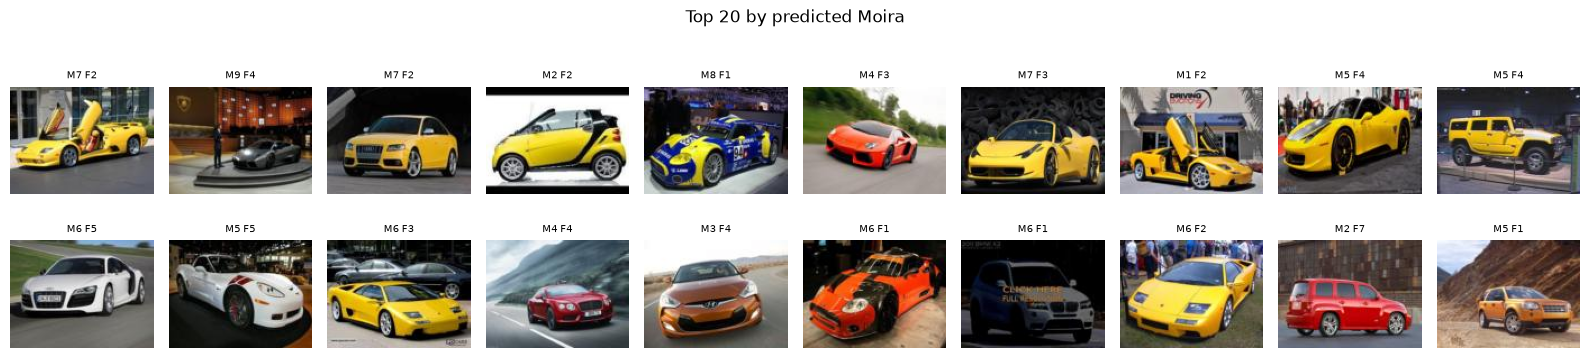

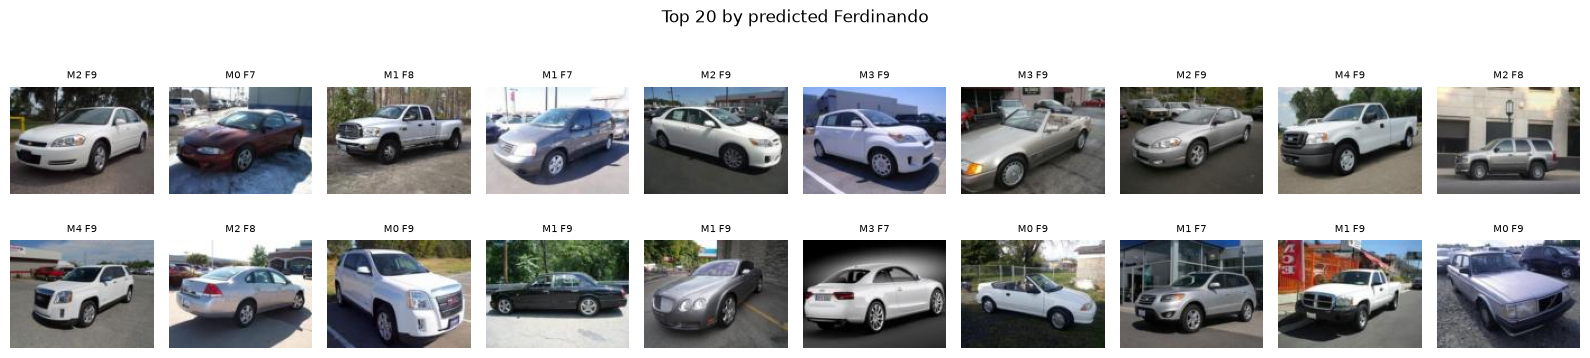

In [15]:
order = P[:, MOIRA].argsort()[::-1][:20]
show(data, [test_idx[i] for i in order], "Top 20 by predicted Moira")

order = P[:, FERDINANDO].argsort()[::-1][:20]
show(data, [test_idx[i] for i in order], "Top 20 by predicted Ferdinando")
plt.show()